# Jaccard fact checker (Part 1), version 2

## 1. Imports

In [1]:
import json, re, csv, time
from pathlib import Path
from collections import Counter
from functools import lru_cache
from itertools import product
from math import log

import numpy as np
import matplotlib.pyplot as plt
import nltk
from nltk.stem import PorterStemmer

SEED = 42
np.random.seed(SEED)

OUT_DIR = Path("results"); OUT_DIR.mkdir(exist_ok=True)
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)

## 1b. Table helper (shows tables in the notebook and collects them for `answers.md`)

In [2]:
from IPython.display import display, Markdown

ANSWERS_PATH = Path("answers.md")         # new file next to this notebook (Task_A/tamadhi_jaccard/answers.md); Task_A/answers.md is not touched
REPORT = {}                               # heading -> markdown, filled by show(); written out in the last cell

def md_table(headers, rows):
    esc = lambda v: str(v).replace("|", "\\|")
    lines = ["| " + " | ".join(headers) + " |", "|" + "|".join("---" for _ in headers) + "|"]
    lines += ["| " + " | ".join(esc(v) for v in r) + " |" for r in rows]
    return "\n".join(lines)

def show(heading, headers, rows, note=""):
    """Render a table in the notebook and store it for answers.md (re-running a cell replaces its table)."""
    text = md_table(headers, rows) + (f"\n\n{note}" if note else "")
    REPORT[heading] = text
    display(Markdown(f"### {heading}\n\n{text}"))

f3 = lambda x: f"{x:.3f}"
f4 = lambda x: f"{x:.4f}"

## 2. NLTK tokenizer data (downloads only if missing)

In [3]:
for pkg in ["punkt", "punkt_tab"]:
    try:
        nltk.data.find(f"tokenizers/{pkg}")
    except LookupError:
        nltk.download(pkg, quiet=True)
print("NLTK ready")

NLTK ready


## 3. Load the data

In [4]:
# This notebook lives in Task_A/tamadhi_jaccard/, so ../../data is the project's data folder.
DATA_DIR = Path("../../data").resolve()
dev_file = DATA_DIR / "dev_labeled_ChatGPT.jsonl"
passages_file = DATA_DIR / "passages_bm25_ChatGPT_humfacts.jsonl"

def read_jsonl(path):
    records = []
    with open(path, "r", encoding="utf-8") as f:
        for n, line in enumerate(f, start=1):
            line = line.strip()
            if not line:
                continue
            try:
                records.append(json.loads(line))
            except json.JSONDecodeError as e:
                raise ValueError(f"Invalid JSON in {path} line {n}: {e}")
    return records

dev_data = read_jsonl(dev_file)
passages_data = read_jsonl(passages_file)
print(f"Loaded {len(dev_data)} development records and {len(passages_data)} passage records.")

Loaded 31 development records and 5427 passage records.


## 4. Build the examples (IR counts as NS)

In [5]:
BINARY_LABEL_MAP = {"S": 1, "NS": 0, "IR": 0}

fact_to_passage = {}
for record in passages_data:
    if isinstance(record.get("sent"), str):
        fact_to_passage[record["sent"]] = record.get("passages") or []

examples = []
observed = Counter()
for record in dev_data:
    annotations = record.get("annotations") or []
    if isinstance(annotations, dict):
        annotations = [annotations]
    for ann in annotations:
        for fact in ann.get("human-atomic-facts") or []:
            text, label = fact.get("text"), str(fact.get("label", "")).strip().upper()
            if not text or label not in BINARY_LABEL_MAP or text not in fact_to_passage:
                continue
            observed[label] += 1
            examples.append({
                "fact": text,
                "passages": fact_to_passage[text],
                "label": label,
                "gold_binary": BINARY_LABEL_MAP[label],
                "topic": record.get("topic", ""),      # biography, used for grouped CV
            })

y_true = np.array([ex["gold_binary"] for ex in examples], dtype=int)
N_FACTS = len(examples)
show("Data", ["Item", "Count"], [
    ["Facts", N_FACTS],
    ["Biographies", len({ex["topic"] for ex in examples})],
    ["Gold S", observed["S"]], ["Gold NS", observed["NS"]], ["Gold IR (counted as NS)", observed["IR"]],
    ["Binary S / NS", f"{int(y_true.sum())} / {int((y_true == 0).sum())}"],
])

### Data

| Item | Count |
|---|---|
| Facts | 221 |
| Biographies | 31 |
| Gold S | 112 |
| Gold NS | 93 |
| Gold IR (counted as NS) | 16 |
| Binary S / NS | 112 / 109 |

## 5. Tokenizers (cached, so the grid search is fast)

In [6]:
# Conservative stopword list. Negations (not, no, never) are deliberately kept.
STOPWORDS = set("""
a an the and or but if then else when while
is am are was were be been being
to of in on at by for from with as
it its this that these those
he she they them their we our you your
i me my
""".split())

stemmer = PorterStemmer()
_stem_cache = {}
def stem(t):
    s = _stem_cache.get(t)
    if s is None:
        s = _stem_cache[t] = stemmer.stem(t)
    return s

def raw_tokens(text, tokenizer):
    text = text.lower() if isinstance(text, str) else ""
    text = re.sub(r"<[^>]+>", " ", text)                     # strip <s> ... </s> tags
    if tokenizer == "regex":
        return re.sub(r"[^a-z0-9\s]", " ", text).split()
    return [t for t in nltk.word_tokenize(text) if re.fullmatch(r"[a-z0-9]+", t)]

@lru_cache(maxsize=None)
def tokenize(text, tokenizer="nltk", remove_stop=True, stem_on=True):
    toks = raw_tokens(text, tokenizer)
    if remove_stop:
        toks = [t for t in toks if t not in STOPWORDS]
    if stem_on:
        toks = [stem(t) for t in toks]
    return tuple(toks)

for s in ["The cat is not sleeping.", "Gerhard Fischer (inventor) founded Fisher Research Laboratory in 1931."]:
    print(s, "->", tokenize(s, "nltk", True, True))

The cat is not sleeping. -> ('cat', 'not', 'sleep')
Gerhard Fischer (inventor) founded Fisher Research Laboratory in 1931. -> ('gerhard', 'fischer', 'inventor', 'found', 'fisher', 'research', 'laboratori', '1931')


## 6. Evidence units and subject-name removal

In [7]:
def split_into_sentences(text):
    """Use the <s>...</s> tags; fall back to punctuation if there are none."""
    if not isinstance(text, str) or not text.strip():
        return []
    tagged = re.findall(r"<s>(.*?)</s>", text, flags=re.DOTALL)
    if tagged:
        return [s.strip() for s in tagged if s.strip()]
    parts = re.split(r"(?<=[.!?])\s+", re.sub(r"<[^>]+>", " ", text).strip())
    return [p.strip() for p in parts if p.strip()]

def windows(tokens, size, stride):
    """Overlapping windows of `size` tokens; a short passage is one window, the tail is kept."""
    tokens = list(tokens)
    if len(tokens) <= size:
        return [tokens]
    out = [tokens[i:i + size] for i in range(0, len(tokens) - size + 1, stride)]
    if (len(tokens) - size) % stride:
        out.append(tokens[-size:])
    return out

def title_tokens(passages, tok):
    """Tokens of the page title. A bracketed role such as '(inventor)' is NOT treated as part of the name."""
    names = set()
    for p in passages:
        if isinstance(p, dict):
            title = re.sub(r"\(.*?\)", " ", p.get("title", ""))
            names |= set(tokenize(title, *tok))
    return names

ex0 = examples[0]
print("Fact:", ex0["fact"])
print("Title tokens:", title_tokens(ex0["passages"], ("nltk", True, True)))
print("Sentences in first passage:", len(split_into_sentences(ex0["passages"][0]["text"])))

Fact: Marianne McAndrew is an American.
Title tokens: {'mariann', 'mcandrew'}
Sentences in first passage: 1


## 7. IDF over the unique passages

In [8]:
# Passages repeat for every fact of the same person, so count each passage once.
unique_passages = {}
for rec in passages_data:
    for p in rec.get("passages") or []:
        if isinstance(p, dict) and p.get("text"):
            unique_passages[(p.get("title", ""), p["text"])] = p["text"]
N_DOCS = len(unique_passages)
print("Unique passages:", N_DOCS)

_IDF = {}
def get_idf(tokenizer, remove_stop, stem_on):
    """Smoothed IDF: log((N+1)/(df+1)) + 1. Unseen tokens get the largest weight."""
    key = (tokenizer, remove_stop, stem_on)
    if key not in _IDF:
        df = Counter()
        for text in unique_passages.values():
            df.update(set(tokenize(text, *key)))
        idf = {t: log((N_DOCS + 1) / (c + 1)) + 1 for t, c in df.items()}
        _IDF[key] = (idf, log(N_DOCS + 1) + 1)
    return _IDF[key]

idf_demo, _ = get_idf("nltk", True, True)
for w in ["american", "actor", "born", "metal", "detector"]:
    t = stem(w)
    print(f"{w:<10} idf = {idf_demo.get(t, float('nan')):.2f}")

Unique passages: 1562
american   idf = 3.20
actor      idf = 3.44
born       idf = 2.93
metal      idf = 6.16
detector   idf = 7.26


## 8. Jaccard scorer

In [9]:
def jaccard(a, b, idf=None, default=1.0):
    a, b = set(a), set(b)
    if not a or not b:
        return 0.0
    if idf is None:
        return len(a & b) / len(a | b)
    w = lambda s: sum(idf.get(t, default) for t in s)
    return w(a & b) / w(a | b)

def score_fact(ex, tokenizer="nltk", remove_stop=True, stem_on=True, drop_title=False,
               unit="passage", win=8, stride=4, weighted=False, aggregation="max", top_k=2):
    tok = (tokenizer, remove_stop, stem_on)
    idf, default = get_idf(*tok) if weighted else (None, 1.0)

    fact = list(tokenize(ex["fact"], *tok))
    names = title_tokens(ex["passages"], tok) if drop_title else set()
    if names:
        without = [t for t in fact if t not in names]
        if without:
            fact = without
        else:
            names = set()          # the fact is only the name: keep it on both sides
    if not fact:
        return 0.0

    scores = []
    for p in ex["passages"]:
        text = p.get("text", "") if isinstance(p, dict) else ""
        if unit == "sentence":
            segs = [tokenize(s, *tok) for s in split_into_sentences(text)]
        elif unit == "window":
            segs = windows([t for t in tokenize(text, *tok) if t not in names], win, stride)
        else:
            segs = [tokenize(text, *tok)]
        for seg in segs:
            seg = [t for t in seg if t not in names]
            if seg:
                scores.append(jaccard(fact, seg, idf, default))

    if not scores:
        return 0.0
    if aggregation == "max":
        return max(scores)
    if aggregation == "mean":
        return float(np.mean(scores))
    return float(np.mean(sorted(scores, reverse=True)[:top_k]))     # top-k mean

_SCORES = {}
def score_all(**cfg):
    key = tuple(sorted(cfg.items()))
    if key not in _SCORES:
        _SCORES[key] = np.array([score_fact(ex, **cfg) for ex in examples], dtype=float)
    return _SCORES[key]

ex = next(e for e in examples if e["label"] == "S")
print("Fact:", ex["fact"])
for cfg in [dict(), dict(drop_title=True), dict(drop_title=True, unit="sentence"), dict(drop_title=True, unit="window")]:
    print(f"  {cfg or 'old best (passage, name kept)'}: {score_fact(ex, **cfg):.4f}")

Fact: Marianne McAndrew is an actress.
  old best (passage, name kept): 0.0341
  {'drop_title': True}: 0.0141
  {'drop_title': True, 'unit': 'sentence'}: 0.1000
  {'drop_title': True, 'unit': 'window'}: 0.1250


## 9. Evaluation: metrics, threshold sweep (step 0.001) and cross-validation

In [10]:
GRID = np.round(np.arange(0, 1.0005, 0.001), 3)

def binary_metrics(y, pred):
    tp = int(((pred == 1) & (y == 1)).sum()); fn = int(((pred == 0) & (y == 1)).sum())
    fp = int(((pred == 1) & (y == 0)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    div = lambda a, b: a / b if b else 0.0
    pS, rS = div(tp, tp + fp), div(tp, tp + fn)
    pN, rN = div(tn, tn + fn), div(tn, tn + fp)
    return dict(accuracy=(tp + tn) / len(y), TP=tp, FN=fn, FP=fp, TN=tn,
                precision_S=pS, recall_S=rS, f1_S=div(2 * pS * rS, pS + rS),
                precision_NS=pN, recall_NS=rN, f1_NS=div(2 * pN * rN, pN + rN))

def acc_curve(scores, idx=None):
    idx = np.arange(len(scores)) if idx is None else idx
    return ((scores[idx, None] >= GRID[None, :]) == (y_true[idx, None] == 1)).mean(axis=0)

def tune(scores, idx=None):
    accs = acc_curve(scores, idx)
    b = int(np.argmax(accs))
    return float(GRID[b]), float(accs[b])

def cv_folds(scores, folds):
    out = []
    for test in folds:
        train = np.setdiff1d(np.arange(N_FACTS), test)
        th, _ = tune(scores, train)
        out.append(float(((scores[test] >= th).astype(int) == y_true[test]).mean()))
    return float(np.mean(out)), float(np.std(out)), out

# 5 random folds (seed 42), the same split as the rest of the report
RANDOM_FOLDS = np.array_split(np.random.default_rng(SEED).permutation(N_FACTS), 5)

# 5 folds that hold out whole biographies, so one person is never on both sides
topics = sorted({ex["topic"] for ex in examples})
topic_order = np.random.default_rng(SEED).permutation(len(topics))
topic_fold = {topics[t]: i % 5 for i, t in enumerate(topic_order)}
GROUP_FOLDS = [np.array([i for i, ex in enumerate(examples) if topic_fold[ex["topic"]] == k]) for k in range(5)]

def evaluate(name="", **cfg):
    s = score_all(**cfg)
    th, a = tune(s)
    cv, cv_sd, _ = cv_folds(s, RANDOM_FOLDS)
    gcv, _, _ = cv_folds(s, GROUP_FOLDS)
    m = binary_metrics(y_true, (s >= th).astype(int))
    return dict(name=name, **cfg, theta=th, acc=a, cv=cv, cv_sd=cv_sd, grouped_cv=gcv,
                f1_S=m["f1_S"], precision_S=m["precision_S"], recall_S=m["recall_S"])

print(f"{len(topics)} biographies, fold sizes: random {[len(f) for f in RANDOM_FOLDS]}, grouped {[len(f) for f in GROUP_FOLDS]}")

31 biographies, fold sizes: random [45, 44, 44, 44, 44], grouped [40, 41, 36, 49, 55]


## 10. Baseline: the previous best configuration

In [11]:
OLD_BEST = dict(tokenizer="nltk", remove_stop=True, stem_on=True, drop_title=False,
                unit="passage", weighted=False, aggregation="max")
baseline = evaluate("old best", **OLD_BEST)
show("Baseline: previous best configuration",
     ["Grid step", "theta", "Correct", "Accuracy", "5-fold CV", "Grouped CV", "F1 (S)"],
     [["0.01 (old notebook)", "0.030", f"155/{N_FACTS}", "0.7014", "--", "--", "0.732"],
      ["0.001 (this notebook)", f3(baseline["theta"]), f"{round(baseline['acc'] * N_FACTS)}/{N_FACTS}",
       f4(baseline["acc"]), f"{baseline['cv']:.3f} ± {baseline['cv_sd']:.3f}", f3(baseline["grouped_cv"]), f3(baseline["f1_S"])]],
     note="NLTK tokenizer, stopwords removed, Porter stemming, whole passage, max, name kept, unweighted.")

### Baseline: previous best configuration

| Grid step | theta | Correct | Accuracy | 5-fold CV | Grouped CV | F1 (S) |
|---|---|---|---|---|---|---|
| 0.01 (old notebook) | 0.030 | 155/221 | 0.7014 | -- | -- | 0.732 |
| 0.001 (this notebook) | 0.027 | 159/221 | 0.7195 | 0.696 ± 0.071 | 0.693 | 0.767 |

NLTK tokenizer, stopwords removed, Porter stemming, whole passage, max, name kept, unweighted.

## 11. Main grid search

In [12]:
grid = []
t0 = time.time()
for tokenizer, drop_title, unit, weighted, aggregation in product(
        ["regex", "nltk"], [False, True], ["passage", "sentence", "window"],
        [False, True], ["max", "top2"]):
    cfg = dict(tokenizer=tokenizer, remove_stop=True, stem_on=True, drop_title=drop_title,
               unit=unit, weighted=weighted, aggregation=aggregation)
    if unit == "window":
        cfg.update(win=8, stride=4)
    grid.append(evaluate(**cfg))
print(f"{len(grid)} configs in {time.time() - t0:.0f}s\n")

grid.sort(key=lambda r: (r["acc"], r["cv"]), reverse=True)
show("Grid search: top 15 of 48 configurations",
     ["Rank", "Tokenizer", "Name", "Unit", "IDF", "Aggregation", "theta", "Accuracy", "5-fold CV", "Grouped CV", "F1 (S)"],
     [[i, r["tokenizer"], "removed" if r["drop_title"] else "kept", r["unit"], "yes" if r["weighted"] else "no",
       r["aggregation"], f3(r["theta"]), f4(r["acc"]), f3(r["cv"]), f3(r["grouped_cv"]), f3(r["f1_S"])]
      for i, r in enumerate(grid[:15], 1)],
     note="All rows remove stopwords and stem. Windows are 8 tokens, stride 4. The full grid is in results/grid_v2.csv.")

with open(OUT_DIR / "grid_v2.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=list(grid[0].keys()) + ["win", "stride"], extrasaction="ignore")
    w.writeheader(); w.writerows(grid)

48 configs in 2s



### Grid search: top 15 of 48 configurations

| Rank | Tokenizer | Name | Unit | IDF | Aggregation | theta | Accuracy | 5-fold CV | Grouped CV | F1 (S) |
|---|---|---|---|---|---|---|---|---|---|---|
| 1 | nltk | removed | window | no | top2 | 0.119 | 0.8145 | 0.796 | 0.804 | 0.821 |
| 2 | regex | removed | window | no | top2 | 0.102 | 0.8054 | 0.801 | 0.803 | 0.826 |
| 3 | nltk | removed | window | no | max | 0.112 | 0.8009 | 0.791 | 0.786 | 0.810 |
| 4 | nltk | removed | window | yes | max | 0.100 | 0.7919 | 0.774 | 0.771 | 0.819 |
| 5 | nltk | removed | window | yes | top2 | 0.090 | 0.7919 | 0.769 | 0.781 | 0.819 |
| 6 | regex | removed | window | no | max | 0.112 | 0.7873 | 0.773 | 0.770 | 0.798 |
| 7 | regex | removed | window | yes | max | 0.100 | 0.7873 | 0.760 | 0.752 | 0.814 |
| 8 | regex | removed | window | yes | top2 | 0.092 | 0.7873 | 0.755 | 0.743 | 0.814 |
| 9 | nltk | kept | window | no | top2 | 0.181 | 0.7828 | 0.751 | 0.759 | 0.800 |
| 10 | regex | kept | window | no | top2 | 0.181 | 0.7692 | 0.737 | 0.747 | 0.790 |
| 11 | regex | kept | window | yes | top2 | 0.247 | 0.7466 | 0.728 | 0.737 | 0.748 |
| 12 | regex | kept | window | no | max | 0.167 | 0.7466 | 0.710 | 0.709 | 0.783 |
| 13 | regex | kept | window | yes | max | 0.255 | 0.7421 | 0.719 | 0.733 | 0.749 |
| 14 | nltk | removed | sentence | yes | max | 0.052 | 0.7421 | 0.715 | 0.719 | 0.747 |
| 15 | nltk | removed | sentence | yes | top2 | 0.029 | 0.7376 | 0.733 | 0.714 | 0.752 |

All rows remove stopwords and stem. Windows are 8 tokens, stride 4. The full grid is in results/grid_v2.csv.

## 12. Effect of the name removal and the evidence unit

In [13]:
# Best result for each (name removal, unit) pair, so the two main changes can be read off directly.
rows = []
for unit in ["passage", "sentence", "window"]:
    row = [unit]
    for drop in [False, True]:
        best = max((r for r in grid if r["unit"] == unit and r["drop_title"] == drop), key=lambda r: (r["acc"], r["cv"]))
        row += [f4(best["acc"]), f3(best["cv"])]
    rows.append(row)
show("Name removal and evidence unit",
     ["Unit", "Name kept: acc", "Name kept: CV", "Name removed: acc", "Name removed: CV"], rows,
     note="Best configuration in each cell (tokenizer, IDF and aggregation free).")

### Name removal and evidence unit

| Unit | Name kept: acc | Name kept: CV | Name removed: acc | Name removed: CV |
|---|---|---|---|---|
| passage | 0.7195 | 0.696 | 0.7285 | 0.683 |
| sentence | 0.6923 | 0.660 | 0.7421 | 0.715 |
| window | 0.7828 | 0.751 | 0.8145 | 0.796 |

Best configuration in each cell (tokenizer, IDF and aggregation free).

## 13. Window size

In [14]:
best_window = max((r for r in grid if r["unit"] == "window"), key=lambda r: (r["acc"], r["cv"]))
base_cfg = {k: best_window[k] for k in ["tokenizer", "remove_stop", "stem_on", "drop_title", "weighted", "aggregation"]}

window_rows = []
for win in [4, 6, 8, 10, 12, 16, 20]:
    window_rows.append(evaluate(**base_cfg, unit="window", win=win, stride=max(1, win // 2)))
show("Window size",
     ["Window", "Stride", "theta", "Accuracy", "5-fold CV", "Grouped CV"],
     [[r["win"], r["stride"], f3(r["theta"]), f4(r["acc"]), f3(r["cv"]), f3(r["grouped_cv"])] for r in window_rows],
     note=f"Other settings fixed at the best window row of the grid: {base_cfg}.")

### Window size

| Window | Stride | theta | Accuracy | 5-fold CV | Grouped CV |
|---|---|---|---|---|---|
| 4 | 2 | 0.191 | 0.7964 | 0.773 | 0.771 |
| 6 | 3 | 0.143 | 0.8054 | 0.787 | 0.799 |
| 8 | 4 | 0.119 | 0.8145 | 0.796 | 0.804 |
| 10 | 5 | 0.096 | 0.8100 | 0.792 | 0.810 |
| 12 | 6 | 0.081 | 0.8190 | 0.819 | 0.820 |
| 16 | 8 | 0.061 | 0.7783 | 0.760 | 0.769 |
| 20 | 10 | 0.055 | 0.7602 | 0.742 | 0.717 |

Other settings fixed at the best window row of the grid: {'tokenizer': 'nltk', 'remove_stop': True, 'stem_on': True, 'drop_title': True, 'weighted': False, 'aggregation': 'top2'}.

## 14. Pick the final configuration

In [15]:
candidates = grid + window_rows
final = max(candidates, key=lambda r: (r["acc"], r["cv"], r["grouped_cv"]))   # dev accuracy, ties broken by CV
FINAL_CFG = {k: final[k] for k in ["tokenizer", "remove_stop", "stem_on", "drop_title", "unit", "weighted", "aggregation"]}
if final["unit"] == "window":
    FINAL_CFG.update(win=final.get("win", 8), stride=final.get("stride", 4))

final_scores = score_all(**FINAL_CFG)
THETA, FINAL_ACC = tune(final_scores)
accs = acc_curve(final_scores)
plateau = GRID[accs == accs.max()]
ok = GRID[accs >= 0.75]

cv, cv_sd, per_fold = cv_folds(final_scores, RANDOM_FOLDS)
gcv, gcv_sd, per_gfold = cv_folds(final_scores, GROUP_FOLDS)

show("Final configuration", ["Setting", "Value"], [
    ["Tokenizer", FINAL_CFG["tokenizer"]],
    ["Stopwords removed", FINAL_CFG["remove_stop"]],
    ["Porter stemming", FINAL_CFG["stem_on"]],
    ["Subject name removed", FINAL_CFG["drop_title"]],
    ["Evidence unit", FINAL_CFG["unit"] + (f" ({FINAL_CFG['win']} tokens, stride {FINAL_CFG['stride']})" if FINAL_CFG["unit"] == "window" else "")],
    ["IDF weighting", FINAL_CFG["weighted"]],
    ["Aggregation", FINAL_CFG["aggregation"]],
    ["Threshold theta", f3(THETA)],
    ["Accuracy", f"{FINAL_ACC:.4f} ({round(FINAL_ACC * N_FACTS)}/{N_FACTS})"],
    ["Best plateau", f"{plateau.min():.3f} to {plateau.max():.3f}"],
    ["theta range with accuracy >= 75%", f"{ok.min():.3f} to {ok.max():.3f}" if len(ok) else "never"],
    ["5-fold CV (seed 42)", f"{cv:.3f} ± {cv_sd:.3f}"],
    ["Grouped CV (whole biographies)", f"{gcv:.3f} ± {gcv_sd:.3f}"],
])
show("Cross-validation folds", ["Fold", "Random folds", "Grouped by biography"],
     [[k, f3(a), f3(g)] for k, (a, g) in enumerate(zip(per_fold, per_gfold), 1)])

### Final configuration

| Setting | Value |
|---|---|
| Tokenizer | nltk |
| Stopwords removed | True |
| Porter stemming | True |
| Subject name removed | True |
| Evidence unit | window (12 tokens, stride 6) |
| IDF weighting | False |
| Aggregation | top2 |
| Threshold theta | 0.081 |
| Accuracy | 0.8190 (181/221) |
| Best plateau | 0.081 to 0.083 |
| theta range with accuracy >= 75% | 0.072 to 0.087 |
| 5-fold CV (seed 42) | 0.819 ± 0.033 |
| Grouped CV (whole biographies) | 0.820 ± 0.040 |

### Cross-validation folds

| Fold | Random folds | Grouped by biography |
|---|---|---|
| 1 | 0.867 | 0.825 |
| 2 | 0.773 | 0.878 |
| 3 | 0.818 | 0.806 |
| 4 | 0.795 | 0.755 |
| 5 | 0.841 | 0.836 |

## 15. One change at a time (ablation for the report)

In [16]:
ablations = [("Final", {})]
ablations.append(("Name kept", {"drop_title": not FINAL_CFG["drop_title"]}))
ablations.append(("No stopword removal", {"remove_stop": False}))
ablations.append(("No stemming", {"stem_on": False}))
ablations.append(("IDF weighting " + ("off" if FINAL_CFG["weighted"] else "on"), {"weighted": not FINAL_CFG["weighted"]}))
ablations.append(("Other tokenizer", {"tokenizer": "regex" if FINAL_CFG["tokenizer"] == "nltk" else "nltk"}))
for u in ["passage", "sentence", "window"]:
    if u != FINAL_CFG["unit"]:
        ablations.append((f"Unit = {u}", {"unit": u, "win": 8, "stride": 4} if u == "window" else {"unit": u}))

ablation_rows = []
for name, change in ablations:
    cfg = {**FINAL_CFG, **change}
    if cfg["unit"] != "window":
        cfg.pop("win", None); cfg.pop("stride", None)
    ablation_rows.append(evaluate(name, **cfg))
show("One change at a time",
     ["Setting", "theta", "Correct", "Accuracy", "5-fold CV", "Grouped CV", "P (S)", "R (S)", "F1 (S)"],
     [[r["name"], f3(r["theta"]), f"{round(r['acc'] * N_FACTS)}/{N_FACTS}", f4(r["acc"]), f3(r["cv"]),
       f3(r["grouped_cv"]), f3(r["precision_S"]), f3(r["recall_S"]), f3(r["f1_S"])] for r in ablation_rows],
     note="Each row is the final configuration with one setting changed; theta is retuned for every row.")

### One change at a time

| Setting | theta | Correct | Accuracy | 5-fold CV | Grouped CV | P (S) | R (S) | F1 (S) |
|---|---|---|---|---|---|---|---|---|
| Final | 0.081 | 181/221 | 0.8190 | 0.819 | 0.820 | 0.786 | 0.884 | 0.832 |
| Name kept | 0.130 | 168/221 | 0.7602 | 0.724 | 0.712 | 0.706 | 0.902 | 0.792 |
| No stopword removal | 0.166 | 151/221 | 0.6833 | 0.642 | 0.625 | 0.681 | 0.705 | 0.693 |
| No stemming | 0.081 | 174/221 | 0.7873 | 0.778 | 0.780 | 0.783 | 0.804 | 0.793 |
| IDF weighting on | 0.067 | 171/221 | 0.7738 | 0.742 | 0.734 | 0.725 | 0.893 | 0.800 |
| Other tokenizer | 0.077 | 175/221 | 0.7919 | 0.792 | 0.786 | 0.746 | 0.893 | 0.813 |
| Unit = passage | 0.020 | 150/221 | 0.6787 | 0.642 | 0.630 | 0.720 | 0.598 | 0.654 |
| Unit = sentence | 0.032 | 154/221 | 0.6968 | 0.696 | 0.654 | 0.674 | 0.777 | 0.722 |

Each row is the final configuration with one setting changed; theta is retuned for every row.

## 16. Final metrics

In [17]:
pred = (final_scores >= THETA).astype(int)
m = binary_metrics(y_true, pred)
show("Per-class results", ["Class", "Precision", "Recall", "F1"],
     [["S", f3(m["precision_S"]), f3(m["recall_S"]), f3(m["f1_S"])],
      ["NS", f3(m["precision_NS"]), f3(m["recall_NS"]), f3(m["f1_NS"])]],
     note=f"Accuracy {m['accuracy']:.4f} ({m['TP'] + m['TN']}/{N_FACTS}).")
show("Confusion matrix", ["", "Predicted S", "Predicted NS"],
     [["Gold S", m["TP"], m["FN"]], ["Gold NS / IR", m["FP"], m["TN"]]])

### Per-class results

| Class | Precision | Recall | F1 |
|---|---|---|---|
| S | 0.786 | 0.884 | 0.832 |
| NS | 0.863 | 0.752 | 0.804 |

Accuracy 0.8190 (181/221).

### Confusion matrix

|  | Predicted S | Predicted NS |
|---|---|---|
| Gold S | 99 | 13 |
| Gold NS / IR | 27 | 82 |

## 17. Plots for the report

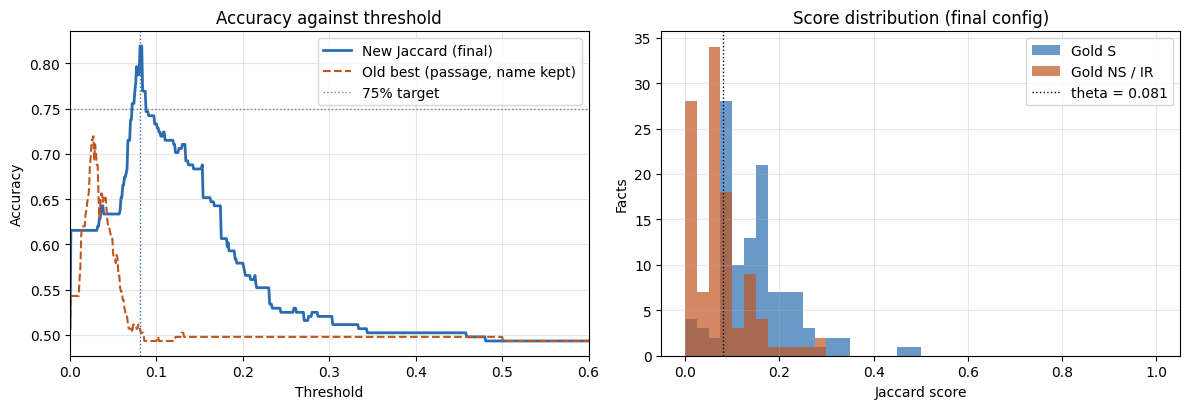

In [18]:
base_scores = score_all(**{k: v for k, v in OLD_BEST.items()})
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))

ax[0].plot(GRID, acc_curve(final_scores), lw=2, color="#2B6CB0", label="New Jaccard (final)")
ax[0].plot(GRID, acc_curve(base_scores), lw=1.5, ls="--", color="#C05621", label="Old best (passage, name kept)")
ax[0].axhline(0.75, color="gray", ls=":", lw=1, label="75% target")
ax[0].axvline(THETA, color="#2B6CB0", ls=":", lw=1)
ax[0].set_xlim(0, max(0.6, THETA * 2)); ax[0].set_xlabel("Threshold"); ax[0].set_ylabel("Accuracy")
ax[0].set_title("Accuracy against threshold"); ax[0].legend(); ax[0].grid(alpha=0.3)

bins = np.linspace(0, 1, 41)
ax[1].hist(final_scores[y_true == 1], bins=bins, alpha=0.7, color="#2B6CB0", label="Gold S")
ax[1].hist(final_scores[y_true == 0], bins=bins, alpha=0.7, color="#C05621", label="Gold NS / IR")
ax[1].axvline(THETA, color="black", ls=":", lw=1, label=f"theta = {THETA:.3f}")
ax[1].set_xlabel("Jaccard score"); ax[1].set_ylabel("Facts")
ax[1].set_title("Score distribution (final config)"); ax[1].legend(); ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / "jaccard_v2.png", dpi=200, bbox_inches="tight")
plt.show()

## 18. Errors

In [19]:
errors = []
for i, ex in enumerate(examples):
    if pred[i] != y_true[i]:
        errors.append({"type": "FP" if pred[i] == 1 else "FN", "fact": ex["fact"],
                       "gold": ex["label"], "score": round(float(final_scores[i]), 4)})

fps = sorted([e for e in errors if e["type"] == "FP"], key=lambda e: -e["score"])
fns = sorted([e for e in errors if e["type"] == "FN"], key=lambda e: e["score"])
show(f"False positives ({len(fps)} in total, 10 highest scores)", ["#", "Fact", "Gold", "Score"],
     [[i, e["fact"], e["gold"], f3(e["score"])] for i, e in enumerate(fps[:10], 1)])
show(f"False negatives ({len(fns)} in total, 10 lowest scores)", ["#", "Fact", "Gold", "Score"],
     [[i, e["fact"], e["gold"], f3(e["score"])] for i, e in enumerate(fns[:10], 1)])

json.dump(errors, open(OUT_DIR / "jaccard_v2_errors.json", "w"), indent=2)

### False positives (27 in total, 10 highest scores)

| # | Fact | Gold | Score |
|---|---|---|---|
| 1 | Gerhard Fischer invented the first handheld, battery-operated metal detector in 1931. | NS | 0.279 |
| 2 | The Fischer Research Laboratory was founded in 1936. | NS | 0.275 |
| 3 | With CSKA, he won three Russian Premier League titles. | NS | 0.258 |
| 4 | He has worked at Mayo Clinic. | NS | 0.240 |
| 5 | The Fischer Research Laboratory became one of the world's leading manufacturers of metal detectors. | NS | 0.213 |
| 6 | Trivisonno started his radio career at WIXY 1260 AM. | NS | 0.182 |
| 7 | Cleveland is in Ohio. | IR | 0.174 |
| 8 | Salazar earned 28 caps for the Peru national team. | IR | 0.167 |
| 9 | Mayo Clinic is an organization. | NS | 0.160 |
| 10 | Haagensen began his acting career when he was 15 years old. | NS | 0.153 |

### False negatives (13 in total, 10 lowest scores)

| # | Fact | Gold | Score |
|---|---|---|---|
| 1 | Hibo Wardere is based in the United Kingdom. | S | 0.000 |
| 2 | Florencia Bertotti is an Argentinian. | S | 0.000 |
| 3 | Haagensen later transitioned to television. | S | 0.000 |
| 4 | They divorced in 1964. | S | 0.000 |
| 5 | Jean Daullé was born in 1703. | S | 0.038 |
| 6 | Jean Daullé died in 1763. | S | 0.038 |
| 7 | Jonathan Haagensen is a Brazilian. | S | 0.042 |
| 8 | He served for many years as a pastor. | S | 0.071 |
| 9 | Haagensen later transitioned to film. | S | 0.074 |
| 10 | Rennie Fritchie is a public servant. | S | 0.077 |

## 19. Save predictions and a summary

In [20]:
with open(OUT_DIR / "final_predictions_v2.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(["fact", "gold_label", "gold_binary", "score", "pred_label", "correct"])
    for ex, s, p in zip(examples, final_scores, pred):
        w.writerow([ex["fact"], ex["label"], ex["gold_binary"], f"{s:.6f}",
                    "S" if p else "NS", "yes" if p == ex["gold_binary"] else "no"])

summary = dict(config=FINAL_CFG, theta=THETA, accuracy=FINAL_ACC, cv=cv, cv_sd=cv_sd,
               grouped_cv=gcv, plateau=[float(plateau.min()), float(plateau.max())],
               metrics=m, baseline=dict(theta=baseline["theta"], acc=baseline["acc"], cv=baseline["cv"]))
json.dump(summary, open(OUT_DIR / "jaccard_v2_summary.json", "w"), indent=2, default=float)
print("Saved results/final_predictions_v2.csv and results/jaccard_v2_summary.json")

Saved results/final_predictions_v2.csv and results/jaccard_v2_summary.json


## 20. LaTeX rows for the report (ablation table)

In [21]:
print(r"\begin{tabular}{lrrrrr}")
print(r"\toprule")
print(r"Setting & $\theta$ & Correct & Dev. & CV & F1 \\")
print(r"\midrule")
for r in ablation_rows:
    name = r"\textbf{" + r["name"] + "}" if r["name"] == "Final" else r["name"]
    print(f"{name} & {r['theta']:.3f} & {round(r['acc'] * N_FACTS)}/{N_FACTS} & {r['acc']:.3f} & {r['cv']:.3f} & {r['f1_S']:.3f} \\\\")
print(r"\midrule")
print(f"Old best (passage, name kept, 0.01 grid) & 0.030 & 155/{N_FACTS} & 0.701 & -- & 0.732 \\\\")
print(r"\bottomrule")
print(r"\end{tabular}")

\begin{tabular}{lrrrrr}
\toprule
Setting & $\theta$ & Correct & Dev. & CV & F1 \\
\midrule
\textbf{Final} & 0.081 & 181/221 & 0.819 & 0.819 & 0.832 \\
Name kept & 0.130 & 168/221 & 0.760 & 0.724 & 0.792 \\
No stopword removal & 0.166 & 151/221 & 0.683 & 0.642 & 0.693 \\
No stemming & 0.081 & 174/221 & 0.787 & 0.778 & 0.793 \\
IDF weighting on & 0.067 & 171/221 & 0.774 & 0.742 & 0.800 \\
Other tokenizer & 0.077 & 175/221 & 0.792 & 0.792 & 0.813 \\
Unit = passage & 0.020 & 150/221 & 0.679 & 0.642 & 0.654 \\
Unit = sentence & 0.032 & 154/221 & 0.697 & 0.696 & 0.722 \\
\midrule
Old best (passage, name kept, 0.01 grid) & 0.030 & 155/221 & 0.701 & -- & 0.732 \\
\bottomrule
\end{tabular}


## 21. Findings (written from the results above)

In [22]:
F = []
base_m = binary_metrics(y_true, (base_scores >= baseline["theta"]).astype(int))
n_base, n_final = round(baseline["acc"] * N_FACTS), round(FINAL_ACC * N_FACTS)

# 1. Overall change
F.append(f"**Overall:** accuracy rose from {baseline['acc']:.3f} ({n_base}/{N_FACTS}) with the previous best setting to "
         f"{FINAL_ACC:.3f} ({n_final}/{N_FACTS}), {n_final - n_base:+d} fact(s), "
         + ("above" if FINAL_ACC >= 0.75 else "below") + " the 75% target. "
         f"5-fold CV rose from {baseline['cv']:.3f} to {cv:.3f}.")

# 2. Name removal
best_by = lambda **c: max((r for r in grid if all(r[k] == v for k, v in c.items())), key=lambda r: (r["acc"], r["cv"]))
kept, removed = best_by(drop_title=False), best_by(drop_title=True)
F.append(f"**Name removal:** the best setting that keeps the subject's name scores {kept['acc']:.3f}; the best that removes it "
         f"scores {removed['acc']:.3f} ({round((removed['acc'] - kept['acc']) * N_FACTS):+d} fact(s)). The name occurs in almost "
         f"every retrieved passage, so keeping it makes unsupported facts look supported.")

# 3. Evidence unit
units = {u: best_by(drop_title=True, unit=u) for u in ["passage", "sentence", "window"]}
best_u = max(units, key=lambda u: (units[u]["acc"], units[u]["cv"]))
F.append("**Evidence unit (name removed):** " + ", ".join(f"{u} {units[u]['acc']:.3f}" for u in units)
         + f". The {best_u} unit is best."
         + (" Jaccard divides by the union, so a long passage makes every score small; "
            "a shorter unit keeps the union close to the size of the fact." if best_u != "passage" else ""))

# 4. Window size
bw = max(window_rows, key=lambda r: (r["acc"], r["cv"]))
F.append("**Window size:** " + ", ".join(f"{r['win']} words {r['acc']:.3f}" for r in window_rows)
         + f". The best is {bw['win']} words (stride {bw['stride']}).")

# 5. One change at a time
final_row = ablation_rows[0]
effects = sorted(((round((r["acc"] - final_row["acc"]) * N_FACTS), r["name"]) for r in ablation_rows[1:]))
F.append("**One change at a time (facts gained or lost vs the final setting):** "
         + "; ".join(f"{name} {d:+d}" for d, name in effects) + ".")

# 6. Robustness
F.append(f"**Robustness:** 5-fold CV is {cv:.3f} ± {cv_sd:.3f} and CV with whole biographies held out is {gcv:.3f}, "
         f"against {FINAL_ACC:.3f} on the full set, so the result is not an artefact of tuning on all {N_FACTS} facts. "
         f"The best threshold plateau is {plateau.min():.3f}–{plateau.max():.3f}"
         + (f"; accuracy stays at or above 75% for theta between {ok.min():.3f} and {ok.max():.3f}." if len(ok) else "."))

# 7. Errors
zero_fn = sum(1 for e in fns if e["score"] == 0)
text = f"**Errors:** false positives went from {base_m['FP']} to {m['FP']} and false negatives from {base_m['FN']} to {m['FN']}."
if fps:
    text += (" The remaining false positives share the content words but differ in a detail word overlap cannot check "
             f"(highest: \"{fps[0]['fact']}\", score {fps[0]['score']:.3f}).")
if zero_fn:
    first_zero = next(e for e in fns if e["score"] == 0)
    text += (f" {zero_fn} false negatives score 0 because the fact and the passage use different words for the same thing "
             f"(e.g. \"{first_zero['fact']}\").")
F.append(text)

display(Markdown("### Findings\n\n" + "\n\n".join(f"{i}. {t}" for i, t in enumerate(F, 1))))
FINDINGS = F

### Findings

1. **Overall:** accuracy rose from 0.719 (159/221) with the previous best setting to 0.819 (181/221), +22 fact(s), above the 75% target. 5-fold CV rose from 0.696 to 0.819.

2. **Name removal:** the best setting that keeps the subject's name scores 0.783; the best that removes it scores 0.814 (+7 fact(s)). The name occurs in almost every retrieved passage, so keeping it makes unsupported facts look supported.

3. **Evidence unit (name removed):** passage 0.729, sentence 0.742, window 0.814. The window unit is best. Jaccard divides by the union, so a long passage makes every score small; a shorter unit keeps the union close to the size of the fact.

4. **Window size:** 4 words 0.796, 6 words 0.805, 8 words 0.814, 10 words 0.810, 12 words 0.819, 16 words 0.778, 20 words 0.760. The best is 12 words (stride 6).

5. **One change at a time (facts gained or lost vs the final setting):** Unit = passage -31; No stopword removal -30; Unit = sentence -27; Name kept -13; IDF weighting on -10; No stemming -7; Other tokenizer -6.

6. **Robustness:** 5-fold CV is 0.819 ± 0.033 and CV with whole biographies held out is 0.820, against 0.819 on the full set, so the result is not an artefact of tuning on all 221 facts. The best threshold plateau is 0.081–0.083; accuracy stays at or above 75% for theta between 0.072 and 0.087.

7. **Errors:** false positives went from 52 to 27 and false negatives from 10 to 13. The remaining false positives share the content words but differ in a detail word overlap cannot check (highest: "Gerhard Fischer invented the first handheld, battery-operated metal detector in 1931.", score 0.279). 4 false negatives score 0 because the fact and the passage use different words for the same thing (e.g. "Hibo Wardere is based in the United Kingdom.").

## 22. Write `answers.md` (next to this notebook)

In [23]:
order = ["Data", "Baseline: previous best configuration", "Grid search: top 15 of 48 configurations",
         "Name removal and evidence unit", "Window size", "Final configuration", "Cross-validation folds",
         "One change at a time", "Per-class results", "Confusion matrix"]
order += [h for h in REPORT if h not in order]          # error tables, in run order

parts = ["# Part 1: Jaccard similarity (Tamadhi), version 2", "",
         f"_Generated by jaccard_experiments_v2.ipynb on {time.strftime('%Y-%m-%d %H:%M')}._", "",
         "## Findings", ""]
parts += [f"{i}. {t}" for i, t in enumerate(FINDINGS, 1)] + ["", "## Results", ""]
for h in order:
    if h in REPORT:
        parts += [f"### {h}", "", REPORT[h], ""]
parts += ["### Figure", "", "![Accuracy against threshold and score distribution](figures/jaccard_v2.png)", ""]

ANSWERS_PATH.write_text("\n".join(parts), encoding="utf-8")      # overwritten on every run
print(f"Wrote {len(FINDINGS)} findings and {len(REPORT)} tables to {ANSWERS_PATH.resolve()}")

Wrote 7 findings and 12 tables to C:\Users\Thamadhi\Documents\YEAR 3\SEMESTER 1\CM 3604 – DEEP LEARNING\Coursework\LLMFactChecking\Task_A\tamadhi_jaccard\answers.md
